In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

In [5]:
df = pd.read_csv('data/games.csv')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 2.0 MB


In [7]:
df.columns = df.columns.str.lower()
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


## Transformando o tipo de dados

In [8]:
df['year_of_release'] = df['year_of_release'].astype('Int64')

Aqui a coluna year_of_release representa o ano de lançamento, ela estava como float, mas não podemos ter anos com casas decimais, por isso eu converti para o tipo de dado inteiro.

In [9]:
df['user_score'].unique()

df['user_score'] = df['user_score'].replace('tbd', np.nan)
df['user_score'] = df['user_score'].astype(float) 

Aqui eu tranformei a coluna user_score de object para float. Por conta dela ser uma coluna numérica, não poderia ser do tipo object.

## Tratando valores ausentes

In [10]:
df = df.dropna(subset = ['name', 'genre'])
df_name = df['name'].isna().sum()
df_genre = df['genre'].isna().sum()

print(df_name)
print(df_genre)

0
0


Apaguei todas as linhas das colunas name e genre, pois eram muito poucas linhas, e acredito que não ia fazer diferença na minha análise, ai optei por fazer isso.

In [11]:
df['year_of_release'].isna().sum()

np.int64(269)

Optei por não preencher e nem apagar, pois não tem como inferir o ano de lançamento, e acredito que se preencher, possa dar problema em futura analises.

In [12]:
df['critic_score'].isna().sum()

np.int64(8576)

Aqui são mais de 8 mil valores ausentes, preencher eles pode distorcer os resultados, e não existe valor certo para fazer a substituição desse valores por ser a pontuação critica.

In [13]:
df['user_score'].isna().sum()

np.int64(9123)

Aqui optei por também deixar ausente, pois o jogo ainda não possuia avaliação suficiente.

In [14]:
df['rating'].isna().sum()

np.int64(6764)

Aqui são muitos valores ausentes, e não temos como saber a avaliação correta.

## Calculando o total de vendas

In [15]:
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']
df

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38
...,...,...,...,...,...,...,...,...,...,...,...,...
16710,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16711,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN,0.01
16712,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16713,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN,0.01


# Análise dos dados

## Jogos lançados a cada ano

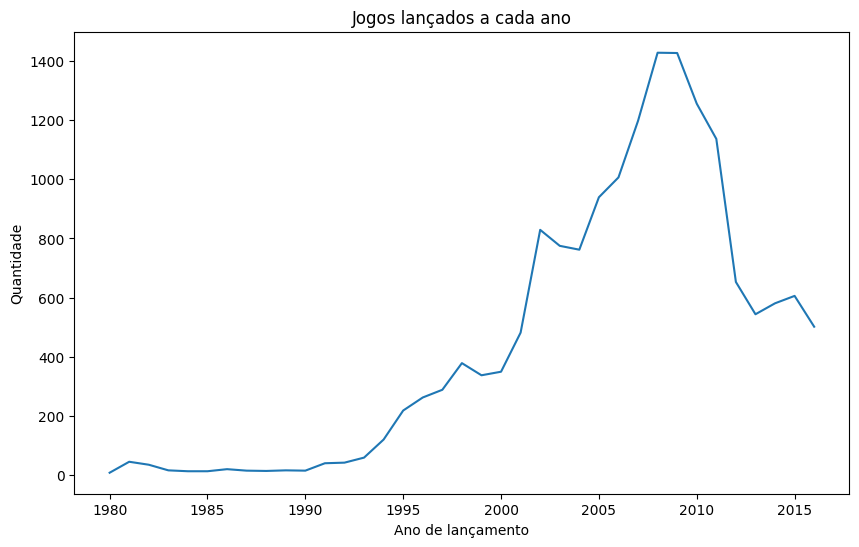

In [16]:
games_per_year = df.groupby('year_of_release')['name'].count()
games_per_year.plot(kind= 'line', figsize=(10, 6))
plt.title('Jogos lançados a cada ano')
plt.xlabel('Ano de lançamento')
plt.ylabel('Quantidade')

plt.show()

Houve um crescimento até 2008-2009, depois o mercado começou a desacelerar.

### Vendas que variam por plataforma

In [17]:
platform_sales = df.groupby('platform')['total_sales'].sum().reset_index()
platform_sales.sort_values(by='total_sales', ascending=False)

,platform,total_sales
16,PS2,1255.77
28,X360,971.42
17,PS3,939.65
26,Wii,907.51
4,DS,806.12
15,PS,730.86
6,GBA,317.85
18,PS4,314.14
19,PSP,294.05
13,PC,259.52


Aqui podemos ver como as vendas variam por plataforma. Temos uma diferença significativa entre as plataformas.

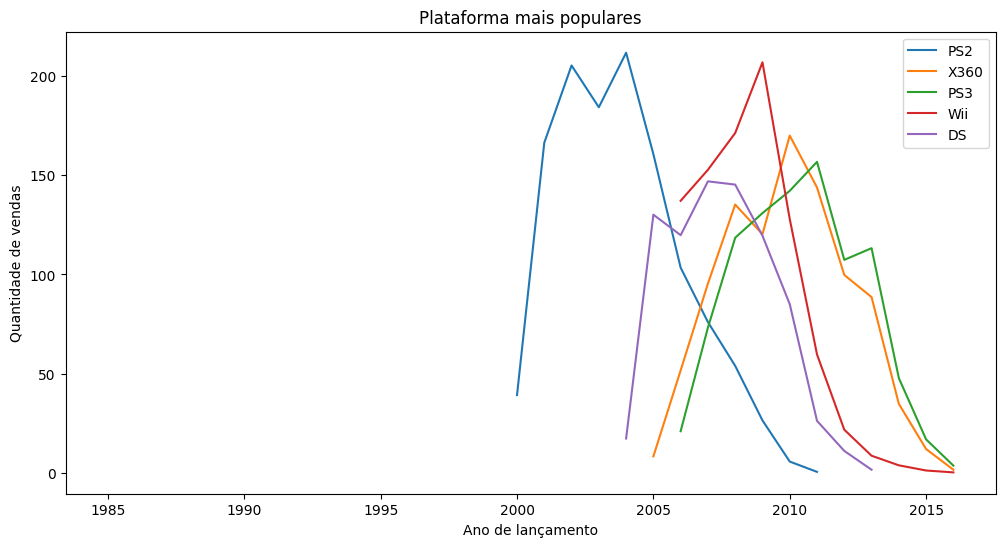

In [18]:
platform_year_sales = df.pivot_table(
    index='year_of_release',
    columns='platform',
    values='total_sales',
    aggfunc='sum'
)
top_platforms = ['PS2', 'X360', 'PS3', 'Wii', 'DS']

platform_year_sales[top_platforms].plot(figsize=(12,6))
plt.title('Plataforma mais populares')
plt.xlabel('Ano de lançamento')
plt.ylabel('Quantidade de vendas')
plt.legend()
plt.show()

Nesse gráfico podemos ver quando a plataforma surgiu, quando atingiu seu pico máximo, quando começou a cair e até mesmo quando deixou de existir. Podemos ver também que o crescimento de uma plataforma leva em torno de uns 2 a 3 anos, o pico de 2 a 4 anos e declinio de 2 a 4 anos também.

## Determinando o periodo para pegar os dados.

In [19]:
recent_games = df[df['year_of_release'] >= 2012]

## Plataforma que lideram em vendas 


In [20]:
platform_top_sales = recent_games.groupby('platform')['total_sales'].sum().reset_index()
platform_top_sales.sort_values(by='total_sales', ascending=False)


,platform,total_sales
4,PS4,314.14
3,PS3,288.79
9,X360,236.54
0,3DS,194.61
10,XOne,159.32
8,WiiU,82.19
2,PC,62.65
6,PSV,49.18
7,Wii,35.37
1,DS,12.55


Podemos verificar que ainda sim, o ps4 continua liderando as vendas em tempos mais modernos.

## Diagrama de caixa para vendas globais de todos os jogos 

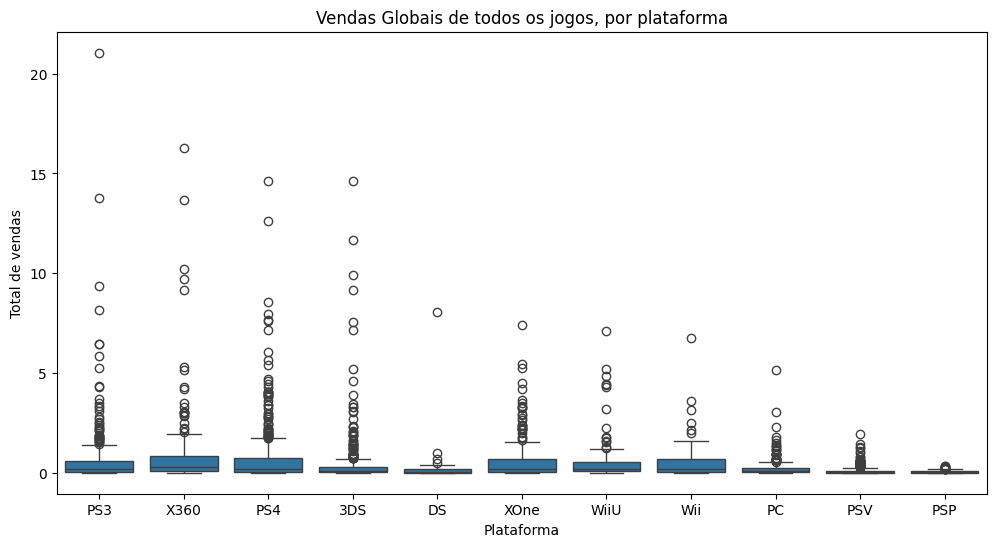

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=recent_games,
    x='platform',
    y='total_sales'
)
plt.title('Vendas Globais de todos os jogos, por plataforma')
plt.xlabel('Plataforma')
plt.ylabel('Total de vendas')

plt.show()

Podemos analisar que as medianas são bem baixas, e temos bastante outliers, ou seja, valores bem acima da mediana.

## Influência das avaliações nas vendas

<Figure size 1200x600 with 0 Axes>

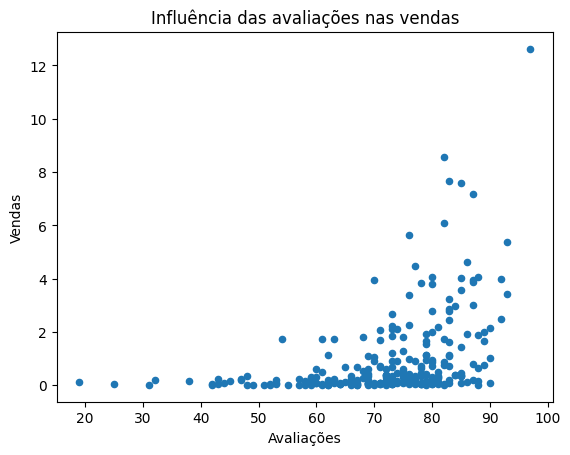

In [22]:
ps4 = recent_games[recent_games['platform'] == 'PS4']

plt.figure(figsize=(12, 6))

ps4.plot(x='critic_score',
        y='total_sales',
        kind='scatter')
plt.title('Influência das avaliações nas vendas')
plt.xlabel('Avaliações')
plt.ylabel('Vendas')
plt.show()

Após analisar o gráfico, vimos que existe uma tendendia fraca positiva, dando a entende que jogos com maiores notas, tendem em alguns casos a aprensentar maiores nota, mas mesmo assim temos bastante ponto dispersos, e que ao analisar isso, podemos ver que as avaliações não é o ponto determinante para o desenpenho comercial de um jogo.

In [23]:
ps4['critic_score'].corr(ps4['total_sales'])

np.float64(0.4065679020617816)

Existe uma relação real, mas moderada, entre avaliação da crítica e vendas.

In [24]:
ps4['user_score'].corr(ps4['total_sales'])

np.float64(-0.03195711020455643)

Correlação praticamente zero, irrelevante, isso quer dizer que os jogos podem vender muito mesmo com avaliações baixas dos usuários.

## Comparando vendas de outro jogo em outras plataformas

In [25]:
recent_games[recent_games['name'] == 'Grand Theft Auto V']

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97.0,8.2,M,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97.0,8.1,M,16.27
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97.0,8.3,M,12.62
165,Grand Theft Auto V,XOne,2014,Action,2.81,2.19,0.00,0.47,97.0,7.9,M,5.47
1730,Grand Theft Auto V,PC,2015,Action,0.39,0.69,0.00,0.09,96.0,7.9,M,1.17


## Distribuição por gênero

In [26]:
genre_sales = recent_games.groupby('genre')['total_sales'].sum().reset_index()
genre_sales.sort_values(by='total_sales', ascending= False)

,genre,total_sales
0,Action,441.12
8,Shooter,304.73
7,Role-Playing,192.80
10,Sports,181.07
3,Misc,85.04
4,Platform,61.00
6,Racing,53.50
2,Fighting,44.49
9,Simulation,35.12
1,Adventure,29.43


A análise das vendas por gênero mostra que jogos de ação, tiro e esportes concentram as maiores vendas totais, indicando forte apelo comercial e grande base de jogadores. Em contrapartida, gêneros como puzzle e estratégia apresentam vendas mais baixas, mostrando um público de menor alcance comercial.



## Perfil de usuário para cada região

### Top 5 plataformas em cada região

 TOP 5 PLATAFORMAS NA AMÉRICA DO NORTE

In [27]:
top_5_platforms_NA = recent_games.groupby('platform')['na_sales'].sum().reset_index()
top_5_platforms_NA.sort_values(by='na_sales', ascending= False).head()

,platform,na_sales
9,X360,140.05
4,PS4,108.74
3,PS3,103.38
10,XOne,93.12
0,3DS,55.31


TOP 5 PLATAFORMAS NA EUROPA

In [28]:
top_5_platforms_EU = recent_games.groupby('platform')['eu_sales'].sum().reset_index()
top_5_platforms_EU.sort_values(by='eu_sales', ascending= False).head()

,platform,eu_sales
4,PS4,141.09
3,PS3,106.86
9,X360,74.52
10,XOne,51.59
0,3DS,42.64


TOP 5 PLATAFORMAS NO JAPÃO

In [29]:
top_5_platforms_JP = recent_games.groupby('platform')['jp_sales'].sum().reset_index()
top_5_platforms_JP.sort_values(by='jp_sales', ascending= False).head()

,platform,jp_sales
0,3DS,87.79
3,PS3,35.29
6,PSV,21.04
4,PS4,15.96
8,WiiU,13.01


As preferencias variam sigficativamente para cada região:

América do Norte: maior preferência por consoles Xbox e PlayStation, com liderança do X360.

Europa: forte domínio dos consoles PlayStation, especialmente PS4.

Japão: destaque para consoles portáteis, principalmente o 3DS, enquanto Xbox praticamente não tem relevância.

## Top 5 gêneros para cada região

TOP 5 GÊNEROS NA AMÉRICA DO NORTE

In [30]:
top_5_genre_NA = recent_games.groupby('genre')['na_sales'].sum().reset_index()
top_5_genre_NA.sort_values(by='na_sales', ascending= False).head()

,genre,na_sales
0,Action,177.84
8,Shooter,144.77
10,Sports,81.53
7,Role-Playing,64.00
3,Misc,38.19


TOP 5 GÊNEROS NA EUROPA

In [31]:
top_5_genre_EU = recent_games.groupby('genre')['eu_sales'].sum().reset_index()
top_5_genre_EU.sort_values(by='eu_sales', ascending= False).head()

,genre,eu_sales
0,Action,159.34
8,Shooter,113.47
10,Sports,69.09
7,Role-Playing,48.53
6,Racing,27.29


TOP 5 GÊNEROS NO JAPÃO

In [32]:
top_5_genre_JP = recent_games.groupby('genre')['jp_sales'].sum().reset_index()
top_5_genre_JP.sort_values(by='jp_sales', ascending= False).head()

,genre,jp_sales
7,Role-Playing,65.44
0,Action,52.80
3,Misc,12.86
9,Simulation,10.41
2,Fighting,9.44


América do Norte e Europa apresentam preferências muito parecidas, com forte destaque para Action, Shooter e Sports.
Japão possui um perfil distinto, com predominância de Role-Playing, além de maior interesse por Simulation e Fighting.

## ESRB influencia vendas?

In [33]:
ESRB_ratings = recent_games.groupby('rating')[['na_sales', 'jp_sales', 'eu_sales']].sum().reset_index()
ESRB_ratings

,rating,na_sales,jp_sales,eu_sales
0,E,114.37,28.33,113.03
1,E10+,75.70,8.19,55.37
2,M,231.57,21.20,193.96
3,T,66.02,26.02,52.96


As classificações da ESRB afetam as vendas em cada região. Na América do Norte e na Europa, os jogos classificados como M dominam o mercado, enquanto no Japão os jogos classificados como E e T apresentam desempenho relativamente melhor. Isso indica que as preferências dos consumidores variam entre as regiões e que a faixa etária alvo dos jogos influencia seu sucesso comercial em cada mercado.

## Teste de hipóteses 

HIPÓTESE 1 ->  As classificações médias dos usuários das plataformas Xbox One e PC são as mesmas.

In [34]:
xbox = recent_games[recent_games['platform'] == 'XOne']['user_score'].dropna()
pc = recent_games[recent_games['platform'] == 'PC']['user_score'].dropna()

alpha = 0.05

results = st.ttest_ind(xbox, pc,  equal_var=False)

print('Valor p', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')

Valor p 0.5489537965134913
Não podemos rejeitar a hipótese nula


HIPÓTESE 2 -> As classificações médias de usuários para os gêneros Action (ação) e Sports (esportes) são diferentes.

In [35]:
action = recent_games[recent_games['genre'] == 'Action']['user_score'].dropna()

sports = recent_games[recent_games['genre'] == 'Sports']['user_score'].dropna()

alpha = 0.05

results = st.ttest_ind(action, sports, equal_var=False)

print('Valor p ', results.pvalue)
if results.pvalue  < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não podemos rejeitar a hipótese nula')

Valor p  4.2430777657263977e-20
Rejeitamos a hipótese nula


Eu user de limiar alpha 0.05, pois na minha concepção é um valor que oferece um equilibrio razoavel entre ser muito rigoroso e muito permissivo.

## Conclusão geral do projeto

Ao longo da análise dos dados de videogames, foi possível perceber como esse mercado cresceu bastante até por volta de 2008-2009 e depois passou a se estabilizar e mudar seu comportamento, principalmente com a troca de gerações de consoles.

As plataformas têm um ciclo de vida médio de 7 a 10 anos, o que explica por que algumas deixam de ser relevantes enquanto outras ganham espaço. Por isso, para entender melhor o cenário atual e fazer previsões para 2017, os dados mais recentes (2013-2016) foram os mais importantes.

Nesse período mais recente, PS4 e Xbox One se destacaram como as plataformas mais promissoras. Também foi possível ver que as avaliações dos críticos têm uma influência um pouco maior nas vendas do que as avaliações dos usuários.

Em relação aos gêneros, Action e Shooter se mostraram os mais fortes em termos de vendas, enquanto outros gêneros tiveram um desempenho mais baixo. Além disso, ficou claro que os mercados da América do Norte, Europa e Japão têm comportamentos diferentes, tanto na escolha de plataformas quanto nos gêneros preferidos.

Por fim, os testes de hipóteses ajudaram a entender melhor algumas diferenças entre grupos de usuários e gêneros, mostrando quando essas diferenças são ou não estatisticamente significativas.